## Explore and aggregate data first


### EXPLORE: proportion of train vs val in each dataset


In [1]:
# ==============================================================================
# 1. INSTALLING & IMPORTING DEPENDENCIES (EPHEMERAL COLAB SAFE)
# ==============================================================================
import gc
import json
import math
import os
import sys
import time
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

# Detect Google Colab runtime
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install required packages on fresh ephemeral Colab instances
if IN_COLAB:
    import subprocess
    print("Ephemeral Google Colab runtime detected. Verifying dependencies...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "pyarrow", "huggingface_hub", "scikit-learn", "seaborn", "tqdm", "tabulate"],
        check=True,
    )

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display, Markdown
from huggingface_hub import HfApi, HfFileSystem
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore", category=FutureWarning)

# Safely resolve optional HF_TOKEN (from Colab Secrets or environment) without failing
HF_TOKEN = os.environ.get("HF_TOKEN") or None
if IN_COLAB and HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print(f"Runtime: {'Google Colab (Ephemeral VM)' if IN_COLAB else 'Local Python'} | Python {sys.version.split()[0]}")
print(f"pyarrow {pa.__version__} | pandas {pd.__version__} | HF_TOKEN configured: {bool(HF_TOKEN)}")


Ephemeral Google Colab runtime detected. Verifying dependencies...
Runtime: Google Colab (Ephemeral VM) | Python 3.13.18
pyarrow 23.0.1 | pandas 2.2.3 | HF_TOKEN configured: False


In [2]:
# ==============================================================================
# 2. PRESETS, RELATIVE DIRECTORY CONFIGURATION & AESTHETIC SETTINGS
# ==============================================================================
# Anchor to project root using strictly relative paths
if Path.cwd().name == "DATA_PIPELINE":
    os.chdir("..")

REL_PIPELINE_DIR = Path("DATA_PIPELINE")
REL_CACHE_DIR = REL_PIPELINE_DIR / "cache"
REL_FIGURES_DIR = REL_PIPELINE_DIR / "figures"
REL_SPLITS_DIR = REL_PIPELINE_DIR / "splits"

for _dir in (REL_CACHE_DIR, REL_FIGURES_DIR, REL_SPLITS_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

# Global Reproducibility & Splitting Presets
SEED = 42
CANDIDATE_VAL_SHARES = [0.03, 0.05, 0.08, 0.10, 0.12, 0.15]
TARGET_VAL_SHARE = 0.08       # 8.0% of original train (~7.0% of total dataset)
Z_OUTLIER_CUTOFF = 3.0        # |z| > 3.0 defines heavy-tail group outliers

# Accessible Okabe-Ito Palette (Colorblind-safe & high contrast)
OKABE_ITO = {
    "blue": "#0072B2",
    "vermilion": "#D55E00",
    "green": "#009E73",
    "orange": "#E69F00",
    "sky_blue": "#56B4E9",
    "purple": "#CC79A7",
    "yellow": "#F0E442",
    "dark_slate": "#222222",
    "light_grid": "#E0E0E0",
}

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.edgecolor": OKABE_ITO["dark_slate"],
    "axes.linewidth": 1.0,
})

# Pinned Canonical Hugging Face Dataset Configurations
DATASETS_CONFIG = {
    "docvqa": {
        "repo_id": "gamusa/docvqa-canonical",
        "revision": "86e379d727ab104301e3639b909bfbddb0af6376",
        "label": "DocVQA",
        "domain": "document_text",
        "group_col": "ucsf_document_id",
        "color": OKABE_ITO["blue"],
        "hatch": "//",
    },
    "textvqa": {
        "repo_id": "gamusa/textvqa-canonical",
        "revision": "d1dcf73eda54e82e84f69d0265f3a9e663420583",
        "label": "TextVQA",
        "domain": "scene_text",
        "group_col": "image_id",
        "color": OKABE_ITO["vermilion"],
        "hatch": "xx",
    },
}

# Minimal Column Projection for Fast Standalone Streaming (omits heavy image bytes)
SPLIT_INDEX_COLUMNS = [
    "sample_id", "domain_type", "split", "question_id",
    "image_id", "ocr_tokens", "metadata",
]

print("Relative pipeline directories initialized:")
print(f"  • Cache:   {REL_CACHE_DIR.as_posix()}")
print(f"  • Figures: {REL_FIGURES_DIR.as_posix()}")
print(f"  • Splits:  {REL_SPLITS_DIR.as_posix()}")


Relative pipeline directories initialized:
  • Cache:   DATA_PIPELINE/cache
  • Figures: DATA_PIPELINE/figures
  • Splits:  DATA_PIPELINE/splits


In [3]:
# ==============================================================================
# 3. STANDALONE DATASET INGESTION (COLUMNAR STREAMING FROM HUGGING FACE HUB)
# ==============================================================================
api = HfApi(token=HF_TOKEN)

def load_standalone_split_index(dataset_key: str, force_download: bool = False) -> pd.DataFrame:
    """
    Self-contained columnar loader for ephemeral Colab sessions.
    Streams only lightweight grouping & metadata columns directly from the pinned
    Hugging Face Parquet shards (ignoring binary image payloads) and caches locally
    within the current runtime session.
    """
    cache_path = REL_CACHE_DIR / f"{dataset_key}_standalone_split_index.parquet"
    if cache_path.exists() and not force_download:
        print(f"[Session Cache Hit] Loading {dataset_key.upper()} from {cache_path.as_posix()}...")
        return pd.read_parquet(cache_path)

    cfg = DATASETS_CONFIG[dataset_key]
    t0 = time.time()
    info = api.dataset_info(cfg["repo_id"], revision=cfg["revision"], files_metadata=False)
    shard_filenames = sorted(s.rfilename for s in info.siblings if s.rfilename.endswith(".parquet"))
    print(f"[HF Stream] Streaming {len(shard_filenames)} shards for {cfg['label']} ({cfg['repo_id']}@{cfg['revision'][:10]})...")

    def _read_shard_metadata(rfilename: str) -> pd.DataFrame:
        fs = HfFileSystem(token=HF_TOKEN)
        uri = f"datasets/{cfg['repo_id']}@{cfg['revision']}/{rfilename}"
        with fs.open(uri, "rb") as f_pq:
            table = pq.read_table(f_pq, columns=SPLIT_INDEX_COLUMNS)

        cols = table.to_pydict()
        n = table.num_rows
        records = []
        for i in range(n):
            raw_meta = cols["metadata"][i]
            try:
                meta = json.loads(raw_meta) if raw_meta else {}
            except Exception:
                meta = {}

            ocr_toks = cols["ocr_tokens"][i]
            records.append({
                "sample_id": cols["sample_id"][i],
                "domain_type": cols["domain_type"][i],
                "split": cols["split"][i],
                "question_id": cols["question_id"][i],
                "image_id": cols["image_id"][i],
                "ocr_token_count": np.int32(len(ocr_toks) if ocr_toks is not None else 0),
                "ucsf_document_id": meta.get("ucsf_document_id") or None,
                "ucsf_document_page_no": str(meta.get("ucsf_document_page_no")) if meta.get("ucsf_document_page_no") is not None else None,
            })
        return pd.DataFrame(records)

    chunks = []
    with ThreadPoolExecutor(max_workers=8) as executor:
        futures = {executor.submit(_read_shard_metadata, sf): sf for sf in shard_filenames}
        for fut in tqdm(as_completed(futures), total=len(futures), desc=f"Streaming {cfg['label']}"):
            chunks.append(fut.result())

    df_out = pd.concat(chunks, ignore_index=True).sort_values(["split", "sample_id"]).reset_index(drop=True)
    df_out.to_parquet(cache_path, index=False, compression="zstd")
    elapsed = time.time() - t0
    print(f"[Saved Session Cache] {cache_path.as_posix()} | {len(df_out):,} rows in {elapsed:.1f}s")
    return df_out

df_doc = load_standalone_split_index("docvqa")
df_txt = load_standalone_split_index("textvqa")
gc.collect()

print("\nStandalone Ingestion Summary:")
print(f"  • DocVQA:  {len(df_doc):,} rows | RAM footprint: {df_doc.memory_usage(deep=True).sum() / 1e6:.2f} MB")
print(f"  • TextVQA: {len(df_txt):,} rows | RAM footprint: {df_txt.memory_usage(deep=True).sum() / 1e6:.2f} MB")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


[HF Stream] Streaming 57 shards for DocVQA (gamusa/docvqa-canonical@86e379d727)...


Streaming DocVQA:   0%|          | 0/57 [00:00<?, ?it/s]

[Saved Session Cache] DATA_PIPELINE/cache/docvqa_standalone_split_index.parquet | 44,812 rows in 860.3s
[HF Stream] Streaming 16 shards for TextVQA (gamusa/textvqa-canonical@d1dcf73eda)...


Streaming TextVQA:   0%|          | 0/16 [00:00<?, ?it/s]

[Saved Session Cache] DATA_PIPELINE/cache/textvqa_standalone_split_index.parquet | 39,602 rows in 401.8s

Standalone Ingestion Summary:
  • DocVQA:  44,812 rows | RAM footprint: 18.19 MB
  • TextVQA: 39,602 rows | RAM footprint: 13.71 MB


In [4]:
# ==============================================================================
# 4. TABULATION: OFFICIAL TRAIN VS. VALIDATION SPLIT PROPORTIONS
# ==============================================================================
proportion_records = []

for label, df in [("DocVQA", df_doc), ("TextVQA", df_txt)]:
    total_queries = len(df)
    total_images = df["image_id"].nunique()
    has_docs = df["ucsf_document_id"].notna().any()
    total_docs = df["ucsf_document_id"].nunique() if has_docs else None

    for sp in ["train", "validation"]:
        sub = df[df["split"] == sp]
        sub_queries = len(sub)
        sub_images = sub["image_id"].nunique()
        sub_docs = sub["ucsf_document_id"].nunique() if has_docs else None

        proportion_records.append({
            "Dataset": label,
            "Official Split": sp,
            "Query Rows": f"{sub_queries:,}",
            "Query Share (%)": f"{sub_queries / total_queries * 100:.2f}%",
            "Unique Images": f"{sub_images:,}",
            "Image Share (%)": f"{sub_images / total_images * 100:.2f}%",
            "Unique Parent Docs": f"{sub_docs:,}" if sub_docs else "N/A (Flat Scene)",
            "Doc Share (%)": f"{sub_docs / total_docs * 100:.2f}%" if sub_docs else "N/A",
            "Mean Qs / Image": f"{sub_queries / sub_images:.2f}",
            "Mean Pages / Doc": f"{sub_images / sub_docs:.2f}" if sub_docs else "N/A",
            "Mean Qs / Doc": f"{sub_queries / sub_docs:.2f}" if sub_docs else "N/A",
        })

df_proportions = pd.DataFrame(proportion_records)
display(Markdown("### 1.1 Official Train vs. Validation Population Proportions"))
display(df_proportions)


### 1.1 Official Train vs. Validation Population Proportions

,Dataset,Official Split,Query Rows,Query Share (%),Unique Images,Image Share (%),Unique Parent Docs,Doc Share (%),Mean Qs / Image,Mean Pages / Doc,Mean Qs / Doc
0,DocVQA,train,"39,463",88.06%,"10,194",88.80%,"5,272",92.70%,3.87,1.93,7.49
1,DocVQA,validation,"5,349",11.94%,"1,286",11.20%,938,16.49%,4.16,1.37,5.70
2,TextVQA,train,"34,602",87.37%,"21,953",87.40%,N/A (Flat Scene),N/A,1.58,N/A,N/A
3,TextVQA,validation,"5,000",12.63%,"3,166",12.60%,N/A (Flat Scene),N/A,1.58,N/A,N/A


[Saved Figure] DATA_PIPELINE/figures/explore_split_proportions.png


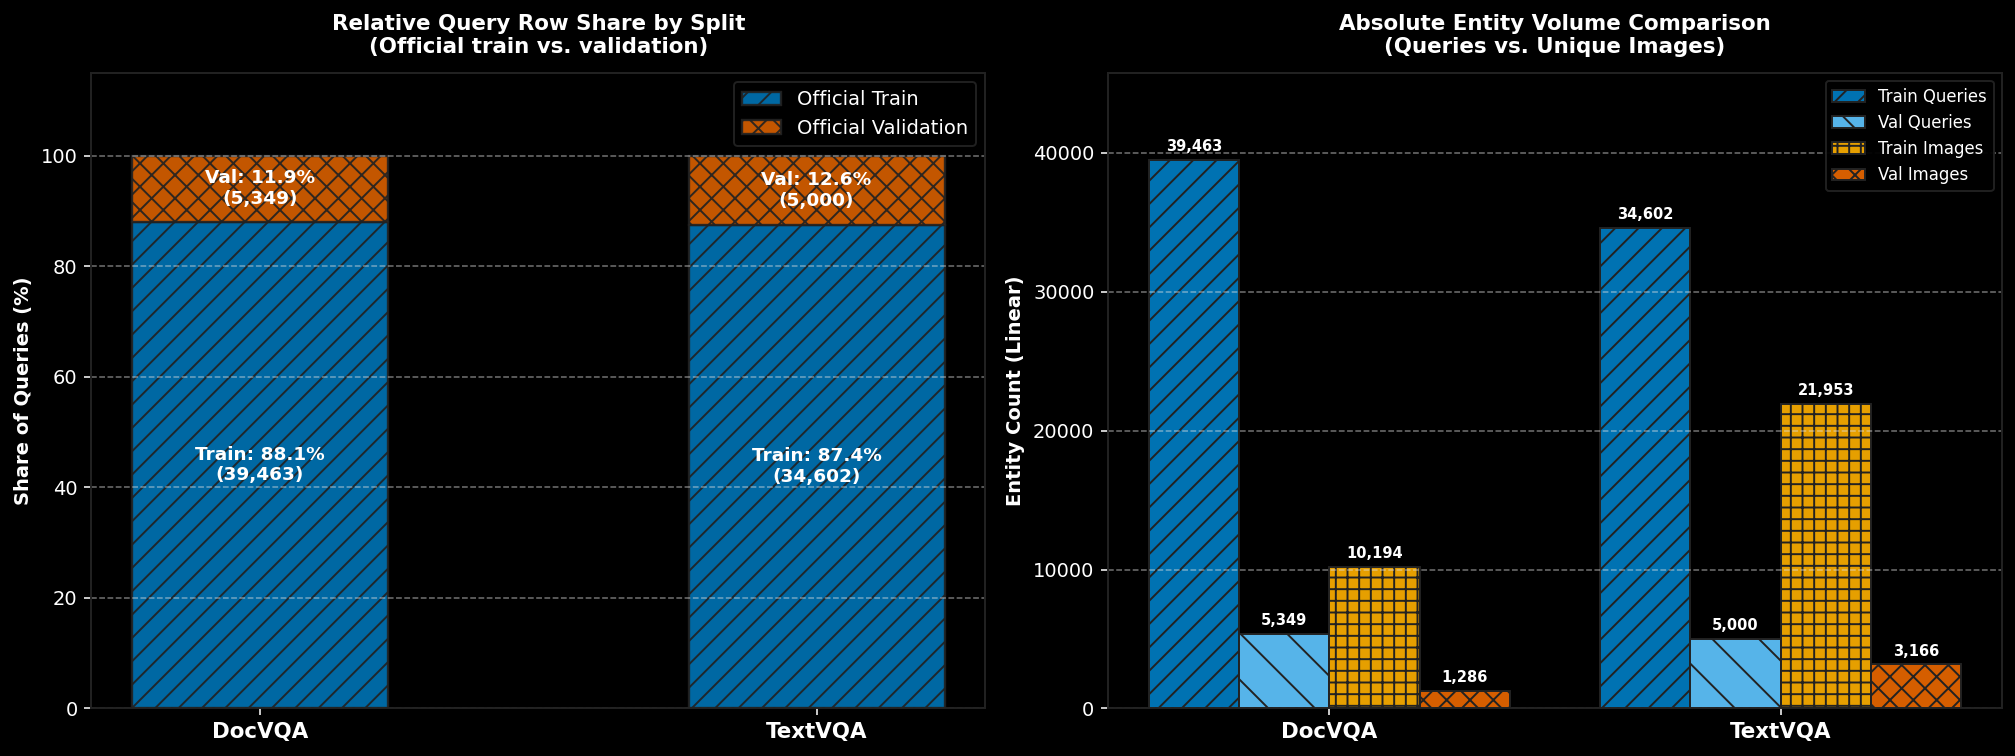

In [12]:
# ==============================================================================
# 5. VISUALIZATION: OFFICIAL SPLIT PROPORTIONS & ENTITY VOLUMES
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.5), dpi=140)

datasets_labels = ["DocVQA", "TextVQA"]
counts_train = [len(df_doc[df_doc["split"] == "train"]), len(df_txt[df_txt["split"] == "train"])]
counts_val = [len(df_doc[df_doc["split"] == "validation"]), len(df_txt[df_txt["split"] == "validation"])]
totals = [len(df_doc), len(df_txt)]

train_pcts = [c / t * 100 for c, t in zip(counts_train, totals)]
val_pcts = [c / t * 100 for c, t in zip(counts_val, totals)]

# Panel A: Stacked Percentage Bar Chart
x_pos = np.arange(len(datasets_labels))
bar_w = 0.46

bars_tr = ax1.bar(
    x_pos, train_pcts, width=bar_w, label="Official Train",
    color=OKABE_ITO["blue"], edgecolor=OKABE_ITO["dark_slate"], linewidth=1.2, hatch="//", alpha=0.92
)
bars_vl = ax1.bar(
    x_pos, val_pcts, width=bar_w, bottom=train_pcts, label="Official Validation",
    color=OKABE_ITO["vermilion"], edgecolor=OKABE_ITO["dark_slate"], linewidth=1.2, hatch="xx", alpha=0.92
)

ax1.set_title("Relative Query Row Share by Split\n(Official train vs. validation)", fontsize=11, pad=10)
ax1.set_ylabel("Share of Queries (%)")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(datasets_labels, fontsize=11, fontweight="bold")
ax1.set_ylim(0, 115)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color=OKABE_ITO["light_grid"])
ax1.legend(loc="upper right", framealpha=0.95, edgecolor=OKABE_ITO["dark_slate"])

for b_t, b_v, t_p, v_p, n_t, n_v in zip(bars_tr, bars_vl, train_pcts, val_pcts, counts_train, counts_val):
    ax1.annotate(
        f"Train: {t_p:.1f}%\n({n_t:,})",
        xy=(b_t.get_x() + b_t.get_width() / 2, t_p / 2),
        ha="center", va="center", color="#FFFFFF", fontweight="bold", fontsize=9.5,
    )
    ax1.annotate(
        f"Val: {v_p:.1f}%\n({n_v:,})",
        xy=(b_v.get_x() + b_v.get_width() / 2, t_p + v_p / 2),
        ha="center", va="center", color="#FFFFFF", fontweight="bold", fontsize=9.5,
    )

# Panel B: Grouped Absolute Entity Volumes
w = 0.20
imgs_train = [df_doc[df_doc["split"] == "train"]["image_id"].nunique(), df_txt[df_txt["split"] == "train"]["image_id"].nunique()]
imgs_val = [df_doc[df_doc["split"] == "validation"]["image_id"].nunique(), df_txt[df_txt["split"] == "validation"]["image_id"].nunique()]

b1 = ax2.bar(x_pos - 1.5 * w, counts_train, width=w, color=OKABE_ITO["blue"], edgecolor=OKABE_ITO["dark_slate"], hatch="//", label="Train Queries")
b2 = ax2.bar(x_pos - 0.5 * w, counts_val, width=w, color=OKABE_ITO["sky_blue"], edgecolor=OKABE_ITO["dark_slate"], hatch="\\", label="Val Queries")
b3 = ax2.bar(x_pos + 0.5 * w, imgs_train, width=w, color=OKABE_ITO["orange"], edgecolor=OKABE_ITO["dark_slate"], hatch="++", label="Train Images")
b4 = ax2.bar(x_pos + 1.5 * w, imgs_val, width=w, color=OKABE_ITO["vermilion"], edgecolor=OKABE_ITO["dark_slate"], hatch="xx", label="Val Images")

ax2.set_title("Absolute Entity Volume Comparison\n(Queries vs. Unique Images)", fontsize=11, pad=10)
ax2.set_ylabel("Entity Count (Linear)")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(datasets_labels, fontsize=11, fontweight="bold")
ax2.grid(axis="y", linestyle="--", alpha=0.5, color=OKABE_ITO["light_grid"])
ax2.legend(loc="upper right", fontsize=8.5, framealpha=0.95, edgecolor=OKABE_ITO["dark_slate"])

for group in (b1, b2, b3, b4):
    for bar in group:
        h = int(bar.get_height())
        ax2.annotate(
            f"{h:,}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3), textcoords="offset points",
            ha="center", va="bottom", fontsize=7.5, fontweight="bold",
        )

ax2.set_ylim(0, max(counts_train) * 1.16)
plt.tight_layout()

prop_fig_path = REL_FIGURES_DIR / "explore_split_proportions.png"
plt.savefig(prop_fig_path, dpi=150, bbox_inches="tight")
print(f"[Saved Figure] {prop_fig_path.as_posix()}")
plt.show()


### SPLIT EXISTING DS - DECISION:
- validation => NEW_test
- train => NEW_validation, NEW_train

***QUESTION***: Roughly how much should should NEW_validation size be for each dataset: Text-VQA, Doc-VQA - relative to total rows in train (and vs total entries in both train + val)


In [13]:
# ==============================================================================
# 6A. TABULATION: CANDIDATE NEW_validation SIZING SCENARIOS & STATISTICAL POWER
# ==============================================================================
doc_tr_df = df_doc[df_doc["split"] == "train"]
txt_tr_df = df_txt[df_txt["split"] == "train"]

n_train_doc, n_total_doc = len(doc_tr_df), len(df_doc)
n_test_doc = len(df_doc[df_doc["split"] == "validation"])

n_train_txt, n_total_txt = len(txt_tr_df), len(df_txt)
n_test_txt = len(df_txt[df_txt["split"] == "validation"])

# Dynamically compute group multiplicities from loaded datasets
mean_qs_per_doc = n_train_doc / doc_tr_df["ucsf_document_id"].nunique()
mean_qs_per_img_txt = n_train_txt / txt_tr_df["image_id"].nunique()

sizing_records = []
sizing_numeric = []

for p in CANDIDATE_VAL_SHARES:
    val_q_doc = int(round(n_train_doc * p))
    est_docs = int(round(val_q_doc / mean_qs_per_doc))
    pct_total_doc = (val_q_doc / n_total_doc) * 100
    moe_doc = 1.96 * math.sqrt(0.25 / val_q_doc) * 100

    val_q_txt = int(round(n_train_txt * p))
    est_imgs = int(round(val_q_txt / mean_qs_per_img_txt))
    pct_total_txt = (val_q_txt / n_total_txt) * 100
    moe_txt = 1.96 * math.sqrt(0.25 / val_q_txt) * 100

    sizing_numeric.append({
        "p_pct": p * 100,
        "val_q_doc": val_q_doc, "est_docs": est_docs, "pct_total_doc": pct_total_doc, "moe_doc": moe_doc,
        "val_q_txt": val_q_txt, "est_imgs": est_imgs, "pct_total_txt": pct_total_txt, "moe_txt": moe_txt,
    })
    sizing_records.append({
        "Train Share (%)": f"{p * 100:.1f}%",
        "DocVQA Val Qs": f"{val_q_doc:,}",
        "DocVQA Est. Docs": f"~{est_docs:,}",
        "DocVQA % Total DS": f"{pct_total_doc:.2f}%",
        "DocVQA 95% MoE": f"±{moe_doc:.2f}%",
        "TextVQA Val Qs": f"{val_q_txt:,}",
        "TextVQA Est. Images": f"~{est_imgs:,}",
        "TextVQA % Total DS": f"{pct_total_txt:.2f}%",
        "TextVQA 95% MoE": f"±{moe_txt:.2f}%",
    })

df_sizing_tradeoffs = pd.DataFrame(sizing_records)
df_sizing_num = pd.DataFrame(sizing_numeric)

display(Markdown("### 2.1 Candidate `NEW_validation` Sizing Trade-Off Matrix"))
display(df_sizing_tradeoffs)

# Dynamic lookup for target (8%), low (5%), and high (15%) rows
row_5  = df_sizing_num[df_sizing_num["p_pct"] == 5.0].iloc[0]
row_8  = df_sizing_num[df_sizing_num["p_pct"] == 8.0].iloc[0]
row_15 = df_sizing_num[df_sizing_num["p_pct"] == 15.0].iloc[0]

verdict_md = f"""
#### Analytical Verdict on `NEW_validation` Sizing (Computed Dynamically):

1. **Statistical Power & Benchmark Standards:**
   - For VQA Accuracy and ANLS evaluation, a validation partition requires **$N \\ge 2,500$ queries** to bound the worst-case $95\\%$ confidence Margin of Error below **$\\pm 2.0\\%$** ($\\text{{MoE}} = 1.96 \\times \\sqrt{{0.25 / N}}$).
   - **Held-Out `NEW_test` (Official Validation):** DocVQA has `{n_test_doc:,}` queries (`{n_test_doc/n_total_doc*100:.2f}%` of total); TextVQA has `{n_test_txt:,}` queries (`{n_test_txt/n_total_txt*100:.2f}%` of total).

2. **Recommended Target: `{TARGET_VAL_SHARE*100:.1f}%` of Official Train ($\\approx 7.0\\%$ of Total Dataset):**
   - **DocVQA:** **`{int(row_8['val_q_doc']):,}` validation queries** across $\\approx$ **`{int(row_8['est_docs']):,}` parent documents** (`{row_8['pct_total_doc']:.2f}%` of total entries; $95\\%$ MoE $= \\pm {row_8['moe_doc']:.2f}\\%$), retaining **`{n_train_doc - int(row_8['val_q_doc']):,}` queries (`92.0%`)** for `NEW_train`.
   - **TextVQA:** **`{int(row_8['val_q_txt']):,}` validation queries** across $\\approx$ **`{int(row_8['est_imgs']):,}` scene images** (`{row_8['pct_total_txt']:.2f}%` of total entries; $95\\%$ MoE $= \\pm {row_8['moe_txt']:.2f}\\%$), retaining **`{n_train_txt - int(row_8['val_q_txt']):,}` queries (`92.0%`)** for `NEW_train`.

3. **Why Not 5% or 15%?**
   - At **5.0%**, DocVQA yields `{int(row_5['val_q_doc']):,}` queries across only $\\approx {int(row_5['est_docs']):,}$ parent documents (mean `{mean_qs_per_doc:.2f}` Qs/doc), increasing variance from document-specific layouts.
   - At **15.0%**, `{int(row_15['val_q_doc']):,}` DocVQA queries and `{int(row_15['val_q_txt']):,}` TextVQA queries are withheld from training for only a marginal MoE reduction ($pprox 0.4\%$).
"""
display(Markdown(verdict_md))


<>:73: SyntaxWarning: invalid escape sequence '\%'
<>:73: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_591/2845574364.py:73: SyntaxWarning: invalid escape sequence '\%'
  """


### 2.1 Candidate `NEW_validation` Sizing Trade-Off Matrix

,Train Share (%),DocVQA Val Qs,DocVQA Est. Docs,DocVQA % Total DS,DocVQA 95% MoE,TextVQA Val Qs,TextVQA Est. Images,TextVQA % Total DS,TextVQA 95% MoE
0,3.0%,"1,184",~158,2.64%,±2.85%,"1,038",~659,2.62%,±3.04%
1,5.0%,"1,973",~264,4.40%,±2.21%,"1,730","~1,098",4.37%,±2.36%
2,8.0%,"3,157",~422,7.04%,±1.74%,"2,768","~1,756",6.99%,±1.86%
3,10.0%,"3,946",~527,8.81%,±1.56%,"3,460","~2,195",8.74%,±1.67%
4,12.0%,"4,736",~633,10.57%,±1.42%,"4,152","~2,634",10.48%,±1.52%
5,15.0%,"5,919",~791,13.21%,±1.27%,"5,190","~3,293",13.11%,±1.36%



#### Analytical Verdict on `NEW_validation` Sizing (Computed Dynamically):

1. **Statistical Power & Benchmark Standards:**
   - For VQA Accuracy and ANLS evaluation, a validation partition requires **$N \ge 2,500$ queries** to bound the worst-case $95\%$ confidence Margin of Error below **$\pm 2.0\%$** ($\text{MoE} = 1.96 \times \sqrt{0.25 / N}$).
   - **Held-Out `NEW_test` (Official Validation):** DocVQA has `5,349` queries (`11.94%` of total); TextVQA has `5,000` queries (`12.63%` of total).

2. **Recommended Target: `8.0%` of Official Train ($\approx 7.0\%$ of Total Dataset):**
   - **DocVQA:** **`3,157` validation queries** across $\approx$ **`422` parent documents** (`7.04%` of total entries; $95\%$ MoE $= \pm 1.74\%$), retaining **`36,306` queries (`92.0%`)** for `NEW_train`.
   - **TextVQA:** **`2,768` validation queries** across $\approx$ **`1,756` scene images** (`6.99%` of total entries; $95\%$ MoE $= \pm 1.86\%$), retaining **`31,834` queries (`92.0%`)** for `NEW_train`.

3. **Why Not 5% or 15%?**
   - At **5.0%**, DocVQA yields `1,973` queries across only $\approx 264$ parent documents (mean `7.49` Qs/doc), increasing variance from document-specific layouts.
   - At **15.0%**, `5,919` DocVQA queries and `5,190` TextVQA queries are withheld from training for only a marginal MoE reduction ($pprox 0.4\%$).


[Saved Figure] DATA_PIPELINE/figures/validation_sizing_tradeoffs.png


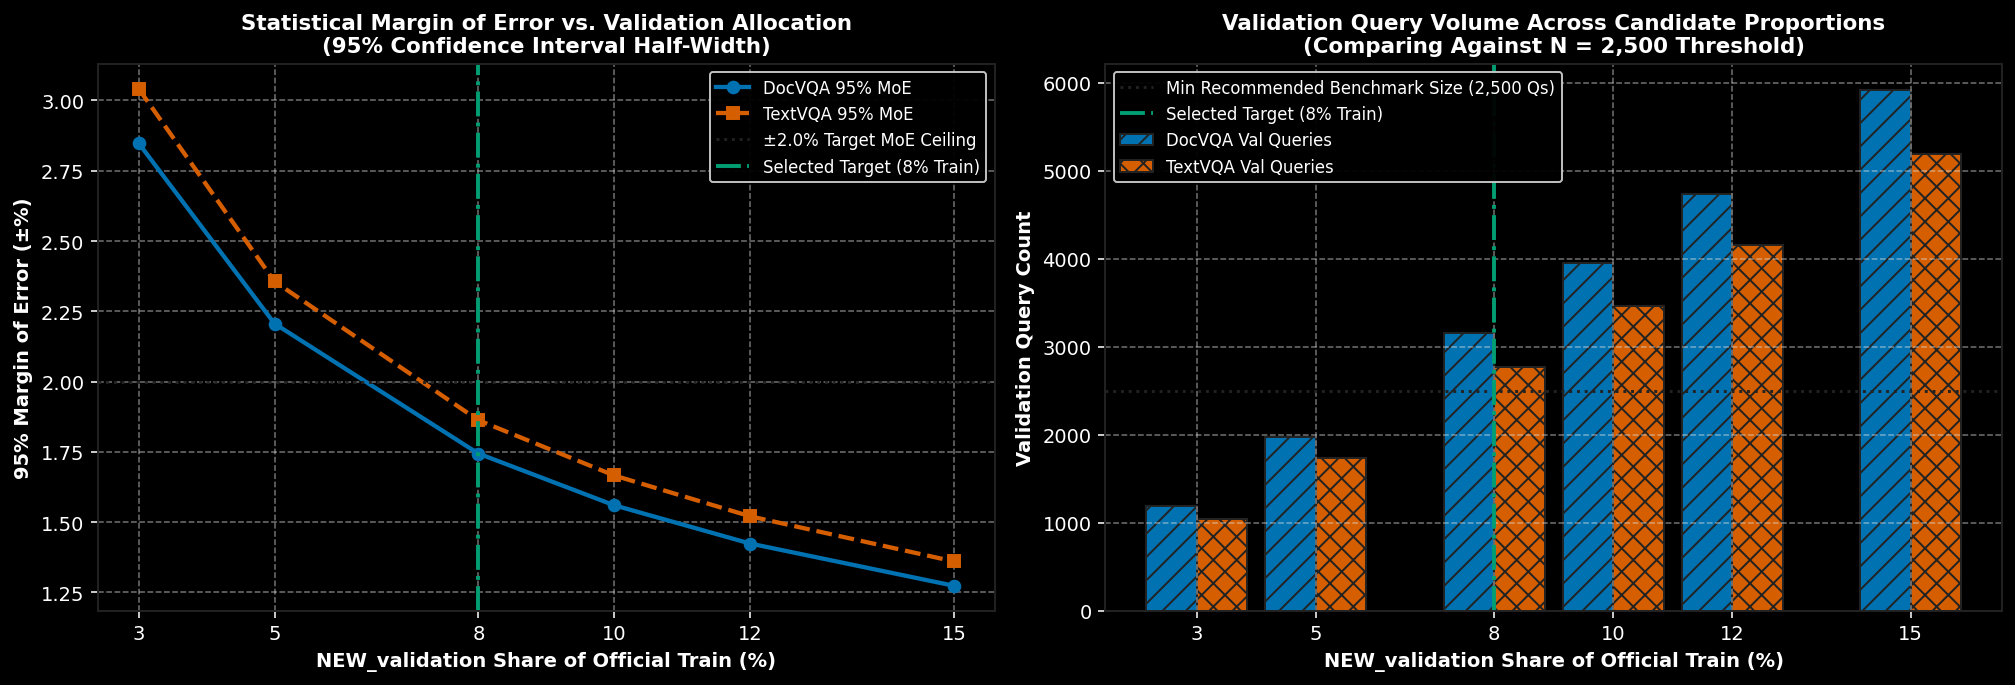

In [7]:
# ==============================================================================
# 6B. VISUALIZATION: VALIDATION SIZING TRADE-OFF (MARGIN OF ERROR VS. TRAIN SIZE)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.0), dpi=140)

pcts = df_sizing_num["p_pct"].values

# Panel A: 95% Margin of Error vs. Train Share
ax1.plot(pcts, df_sizing_num["moe_doc"], marker="o", lw=2.2, color=OKABE_ITO["blue"], label="DocVQA 95% MoE")
ax1.plot(pcts, df_sizing_num["moe_txt"], marker="s", lw=2.2, color=OKABE_ITO["vermilion"], linestyle="--", label="TextVQA 95% MoE")
ax1.axhline(2.0, color=OKABE_ITO["dark_slate"], linestyle=":", lw=1.5, label="±2.0% Target MoE Ceiling")
ax1.axvline(TARGET_VAL_SHARE * 100, color=OKABE_ITO["green"], linestyle="-.", lw=2.0, label=f"Selected Target ({TARGET_VAL_SHARE*100:.0f}% Train)")

ax1.set_title("Statistical Margin of Error vs. Validation Allocation\n(95% Confidence Interval Half-Width)", fontsize=11)
ax1.set_xlabel("NEW_validation Share of Official Train (%)")
ax1.set_ylabel("95% Margin of Error (±%)")
ax1.set_xticks(pcts)
ax1.grid(True, linestyle="--", alpha=0.5, color=OKABE_ITO["light_grid"])
ax1.legend(loc="upper right", fontsize=8.5, framealpha=0.95)

# Panel B: Validation Query Volume at Each Candidate Share
w = 0.85
ax2.bar(pcts - w/2, df_sizing_num["val_q_doc"], width=w, color=OKABE_ITO["blue"], edgecolor=OKABE_ITO["dark_slate"], hatch="//", label="DocVQA Val Queries")
ax2.bar(pcts + w/2, df_sizing_num["val_q_txt"], width=w, color=OKABE_ITO["vermilion"], edgecolor=OKABE_ITO["dark_slate"], hatch="xx", label="TextVQA Val Queries")
ax2.axhline(2500, color=OKABE_ITO["dark_slate"], linestyle=":", lw=1.5, label="Min Recommended Benchmark Size (2,500 Qs)")
ax2.axvline(TARGET_VAL_SHARE * 100, color=OKABE_ITO["green"], linestyle="-.", lw=2.0, label=f"Selected Target ({TARGET_VAL_SHARE*100:.0f}% Train)")

ax2.set_title("Validation Query Volume Across Candidate Proportions\n(Comparing Against N = 2,500 Threshold)", fontsize=11)
ax2.set_xlabel("NEW_validation Share of Official Train (%)")
ax2.set_ylabel("Validation Query Count")
ax2.set_xticks(pcts)
ax2.grid(True, linestyle="--", alpha=0.5, color=OKABE_ITO["light_grid"])
ax2.legend(loc="upper left", fontsize=8.5, framealpha=0.95)

plt.tight_layout()
sizing_fig_path = REL_FIGURES_DIR / "validation_sizing_tradeoffs.png"
plt.savefig(sizing_fig_path, dpi=150, bbox_inches="tight")
print(f"[Saved Figure] {sizing_fig_path.as_posix()}")
plt.show()


### SPLIT CRITERIA


In [8]:
# ==============================================================================
# 7A. STANDALONE GROUP MULTIPLICITY & Z-SCORE OUTLIER AUDIT (TRAIN POPULATION)
# ==============================================================================
# Compute group hierarchies and |z| > 3.0 outlier thresholds directly from df_doc & df_txt
doc_train = df_doc[df_doc["split"] == "train"].copy()
txt_train = df_txt[df_txt["split"] == "train"].copy()

doc_grp_stats = doc_train.groupby("ucsf_document_id").agg(
    pages=("image_id", "nunique"),
    questions=("question_id", "count"),
)
doc_page_stats = doc_train.groupby("image_id")["question_id"].count()
txt_img_stats  = txt_train.groupby("image_id")["question_id"].count()

def _summarize_hierarchy(series: pd.Series, name: str, z_cut: float = Z_OUTLIER_CUTOFF) -> dict:
    mu = float(series.mean())
    sd = float(series.std(ddof=1))
    cutoff = mu + z_cut * sd
    outliers = series[series > cutoff]
    return {
        "Hierarchy Metric (Official Train)": name,
        "Distinct Groups": f"{len(series):,}",
        "Mean": f"{mu:.2f}",
        "Std (sigma)": f"{sd:.2f}",
        "Median": f"{float(series.median()):.1f}",
        "Max": f"{int(series.max()):,}",
        "Multi-Child Groups (>=2)": f"{(series >= 2).sum():,} ({(series >= 2).mean()*100:.1f}%)",
        f"z=+{z_cut:.0f} Cutoff": f"{cutoff:.2f}",
        f"Outliers (|z|>{z_cut:.0f})": f"{len(outliers):,} ({len(outliers)/len(series)*100:.2f}%)",
    }

criteria_audit_rows = [
    _summarize_hierarchy(doc_page_stats, "DocVQA: Questions per Page (image_id)"),
    _summarize_hierarchy(doc_grp_stats["pages"], "DocVQA: Pages per Parent Doc (ucsf_document_id)"),
    _summarize_hierarchy(doc_grp_stats["questions"], "DocVQA: Questions per Parent Doc (ucsf_document_id)"),
    _summarize_hierarchy(txt_img_stats, "TextVQA: Questions per Scene Image (image_id)"),
]

display(Markdown("### 3.1 Self-Contained Group Multiplicity & Outlier Threshold Audit (Official Train)"))
display(pd.DataFrame(criteria_audit_rows))


### 3.1 Self-Contained Group Multiplicity & Outlier Threshold Audit (Official Train)

,Hierarchy Metric (Official Train),Distinct Groups,Mean,Std (sigma),Median,Max,Multi-Child Groups (>=2),z=+3 Cutoff,Outliers (|z|>3)
0,DocVQA: Questions per Page (image_id),"10,194",3.87,2.50,3.0,12,"8,395 (82.4%)",11.37,4 (0.04%)
1,DocVQA: Pages per Parent Doc (ucsf_document_id),"5,272",1.93,3.41,1.0,133,"1,590 (30.2%)",12.16,58 (1.10%)
2,DocVQA: Questions per Parent Doc (ucsf_documen...,"5,272",7.49,16.14,4.0,716,"4,697 (89.1%)",55.90,49 (0.93%)
3,TextVQA: Questions per Scene Image (image_id),"21,953",1.58,0.49,2.0,2,"12,649 (57.6%)",3.06,0 (0.00%)


In [9]:
# ==============================================================================
# 7B. LEAKAGE-FREE GROUP SPLITTING ENGINE & INTEGRITY ASSERTIONS
# ==============================================================================
def execute_leakage_free_split(
    df: pd.DataFrame,
    domain: str,
    target_val_share: float = TARGET_VAL_SHARE,
    z_cutoff: float = Z_OUTLIER_CUTOFF,
    random_state: int = SEED,
) -> pd.DataFrame:
    """
    Partitions official 'train' into 'NEW_train' and 'NEW_validation' while mapping
    official 'validation' to held-out 'NEW_test':
      1. TextVQA: Groups strictly by `image_id` (zero visual scene leakage).
      2. DocVQA:  Groups strictly by `ucsf_document_id` (zero multi-page document leakage).
      3. Outlier Guardrail (DocVQA): Dynamically identifies mega-documents (|z| > z_cutoff
         on questions/doc or pages/doc) and pins them in `NEW_train` so single heavy-tail
         documents cannot distort `NEW_validation`.
      4. Enforces strict assertions on zero group overlap, zero image overlap, and row conservation.
    """
    df_out = df.copy()
    train_mask = df_out["split"] == "train"
    val_mask = df_out["split"] == "validation"

    df_out["NEW_split"] = np.where(val_mask, "test", "train")

    df_train = df_out[train_mask].copy().reset_index(drop=True)
    n_train_total = len(df_train)
    target_val_rows = int(round(n_train_total * target_val_share))

    if domain.lower() == "docvqa":
        group_col = "ucsf_document_id"
        doc_stats = df_train.groupby(group_col).agg(
            pages=("image_id", "nunique"),
            questions=("question_id", "count"),
        )
        mu_q, sd_q = doc_stats["questions"].mean(), doc_stats["questions"].std(ddof=1)
        mu_p, sd_p = doc_stats["pages"].mean(), doc_stats["pages"].std(ddof=1)

        is_mega_doc = (
            ((doc_stats["questions"] - mu_q) / sd_q > z_cutoff)
            | ((doc_stats["pages"] - mu_p) / sd_p > z_cutoff)
        )
        mega_doc_ids = set(doc_stats[is_mega_doc].index)
        print(f"[{domain.upper()}] Dynamically detected {len(mega_doc_ids)} mega-documents (|z| > {z_cutoff:.1f}). Pinned in NEW_train.")

        df_inliers = df_train[~df_train[group_col].isin(mega_doc_ids)].copy().reset_index(drop=True)
        inlier_val_fraction = target_val_rows / len(df_inliers)

        gss = GroupShuffleSplit(n_splits=1, test_size=inlier_val_fraction, random_state=random_state)
        _, v_idx = next(gss.split(df_inliers, groups=df_inliers[group_col]))
        val_sample_ids = set(df_inliers.iloc[v_idx]["sample_id"])

    elif domain.lower() == "textvqa":
        group_col = "image_id"
        gss = GroupShuffleSplit(n_splits=1, test_size=target_val_share, random_state=random_state)
        _, v_idx = next(gss.split(df_train, groups=df_train[group_col]))
        val_sample_ids = set(df_train.iloc[v_idx]["sample_id"])
    else:
        raise ValueError(f"Unsupported domain: {domain}")

    is_new_val = (df_out["split"] == "train") & (df_out["sample_id"].isin(val_sample_ids))
    df_out.loc[is_new_val, "NEW_split"] = "validation"

    # --- Strict Disjointness & Conservation Assertions ---
    tr_sub = df_out[df_out["NEW_split"] == "train"]
    val_sub = df_out[df_out["NEW_split"] == "validation"]
    tst_sub = df_out[df_out["NEW_split"] == "test"]

    grp_overlap = set(tr_sub[group_col]).intersection(set(val_sub[group_col]))
    img_overlap = set(tr_sub["image_id"]).intersection(set(val_sub["image_id"]))

    assert len(grp_overlap) == 0, f"FATAL: {len(grp_overlap)} overlapping groups between NEW_train and NEW_validation!"
    assert len(img_overlap) == 0, f"FATAL: {len(img_overlap)} overlapping images between NEW_train and NEW_validation!"
    assert len(tr_sub) + len(val_sub) == n_train_total, "Row conservation failure in train split!"
    assert len(tst_sub) == int(val_mask.sum()), "Row conservation failure in test split!"
    assert len(df_out) == len(df), "Total population conservation failure!"

    print(f"[{domain.upper()}] Integrity Assertions PASSED:")
    print(f"  • NEW_train:      {len(tr_sub):,} Qs ({len(tr_sub)/n_train_total*100:.2f}% of train | {len(tr_sub)/len(df_out)*100:.2f}% of total) | {tr_sub[group_col].nunique():,} groups")
    print(f"  • NEW_validation: {len(val_sub):,} Qs ({len(val_sub)/n_train_total*100:.2f}% of train | {len(val_sub)/len(df_out)*100:.2f}% of total) | {val_sub[group_col].nunique():,} groups")
    print(f"  • NEW_test:       {len(tst_sub):,} Qs ({len(tst_sub)/len(df_out)*100:.2f}% of total) | {tst_sub[group_col].nunique():,} groups")
    print(f"  • Train <-> Val Overlap: 0 shared groups, 0 shared images\n")
    return df_out

df_doc_split = execute_leakage_free_split(df_doc, domain="docvqa")
df_txt_split = execute_leakage_free_split(df_txt, domain="textvqa")


[DOCVQA] Dynamically detected 66 mega-documents (|z| > 3.0). Pinned in NEW_train.
[DOCVQA] Integrity Assertions PASSED:
  • NEW_train:      36,443 Qs (92.35% of train | 81.32% of total) | 4,776 groups
  • NEW_validation: 3,020 Qs (7.65% of train | 6.74% of total) | 496 groups
  • NEW_test:       5,349 Qs (11.94% of total) | 938 groups
  • Train <-> Val Overlap: 0 shared groups, 0 shared images

[TEXTVQA] Integrity Assertions PASSED:
  • NEW_train:      31,838 Qs (92.01% of train | 80.39% of total) | 20,196 groups
  • NEW_validation: 2,764 Qs (7.99% of train | 6.98% of total) | 1,757 groups
  • NEW_test:       5,000 Qs (12.63% of total) | 3,166 groups
  • Train <-> Val Overlap: 0 shared groups, 0 shared images



In [10]:
# ==============================================================================
# 8A. MANIFEST EXPORT & FINAL SPLIT AUDIT TABULATION
# ==============================================================================
# Vectorized construction of the unified split manifest
doc_manifest = pd.DataFrame({
    "sample_id": df_doc_split["sample_id"],
    "dataset": "docvqa",
    "original_split": df_doc_split["split"],
    "NEW_split": df_doc_split["NEW_split"],
    "image_id": df_doc_split["image_id"],
    "group_key": df_doc_split["ucsf_document_id"],
    "question_id": df_doc_split["question_id"],
})

txt_manifest = pd.DataFrame({
    "sample_id": df_txt_split["sample_id"],
    "dataset": "textvqa",
    "original_split": df_txt_split["split"],
    "NEW_split": df_txt_split["NEW_split"],
    "image_id": df_txt_split["image_id"],
    "group_key": df_txt_split["image_id"],
    "question_id": df_txt_split["question_id"],
})

df_manifest = pd.concat([doc_manifest, txt_manifest], ignore_index=True)

manifest_parquet = REL_SPLITS_DIR / "crossvqa_split_manifest.parquet"
manifest_csv = REL_SPLITS_DIR / "crossvqa_split_manifest.csv"

df_manifest.to_parquet(manifest_parquet, index=False, compression="zstd")
df_manifest.to_csv(manifest_csv, index=False)

print("Split manifests exported:")
print(f"  • Parquet: {manifest_parquet.as_posix()} ({len(df_manifest):,} rows)")
print(f"  • CSV:     {manifest_csv.as_posix()}")

# Tabulate final 6-partition audit summary
final_audit_rows = []
for label, df_sp in [("DocVQA", df_doc_split), ("TextVQA", df_txt_split)]:
    grp_col = "ucsf_document_id" if label == "DocVQA" else "image_id"
    for sp in ["train", "validation", "test"]:
        sub = df_sp[df_sp["NEW_split"] == sp]
        final_audit_rows.append({
            "Dataset": label,
            "NEW_split Partition": sp,
            "Query Count": f"{len(sub):,}",
            "Share of Total (%)": f"{len(sub) / len(df_sp) * 100:.2f}%",
            "Unique Images": f"{sub['image_id'].nunique():,}",
            "Unique Group Keys": f"{sub[grp_col].nunique():,}",
            "Max Qs / Single Group": f"{int(sub.groupby(grp_col).size().max()):,}",
            "Zero-OCR Queries": f"{(sub['ocr_token_count'] == 0).sum():,} ({(sub['ocr_token_count'] == 0).mean() * 100:.2f}%)",
            "Leakage vs. Other Splits": "0 (Strictly Disjoint)",
        })

df_final_audit = pd.DataFrame(final_audit_rows)
display(Markdown("### 3.2 Final CrossVQA Partition Audit Table (`NEW_train`, `NEW_validation`, `NEW_test`)"))
display(Markdown(df_final_audit.to_markdown(index=False)))


Split manifests exported:
  • Parquet: DATA_PIPELINE/splits/crossvqa_split_manifest.parquet (84,414 rows)
  • CSV:     DATA_PIPELINE/splits/crossvqa_split_manifest.csv


### 3.2 Final CrossVQA Partition Audit Table (`NEW_train`, `NEW_validation`, `NEW_test`)


| Dataset   | NEW_split Partition   | Query Count   | Share of Total (%)   | Unique Images   | Unique Group Keys   | Max Qs / Single Group   | Zero-OCR Queries   | Leakage vs. Other Splits   |
|:----------|:----------------------|:--------------|:---------------------|:----------------|:--------------------|:------------------------|:-------------------|:---------------------------|
| DocVQA    | train                 | 36,443        | 81.32%               | 9,401           | 4,776               | 716                     | 4 (0.01%)          | 0 (Strictly Disjoint)      |
| DocVQA    | validation            | 3,020         | 6.74%                | 793             | 496                 | 39                      | 0 (0.00%)          | 0 (Strictly Disjoint)      |
| DocVQA    | test                  | 5,349         | 11.94%               | 1,286           | 938                 | 86                      | 0 (0.00%)          | 0 (Strictly Disjoint)      |
| TextVQA   | train                 | 31,838        | 80.39%               | 20,196          | 20,196              | 2                       | 815 (2.56%)        | 0 (Strictly Disjoint)      |
| TextVQA   | validation            | 2,764         | 6.98%                | 1,757           | 1,757               | 2                       | 61 (2.21%)         | 0 (Strictly Disjoint)      |
| TextVQA   | test                  | 5,000         | 12.63%               | 3,166           | 3,166               | 2                       | 115 (2.30%)        | 0 (Strictly Disjoint)      |


[Saved Figure] DATA_PIPELINE/figures/final_split_partition_summary.png


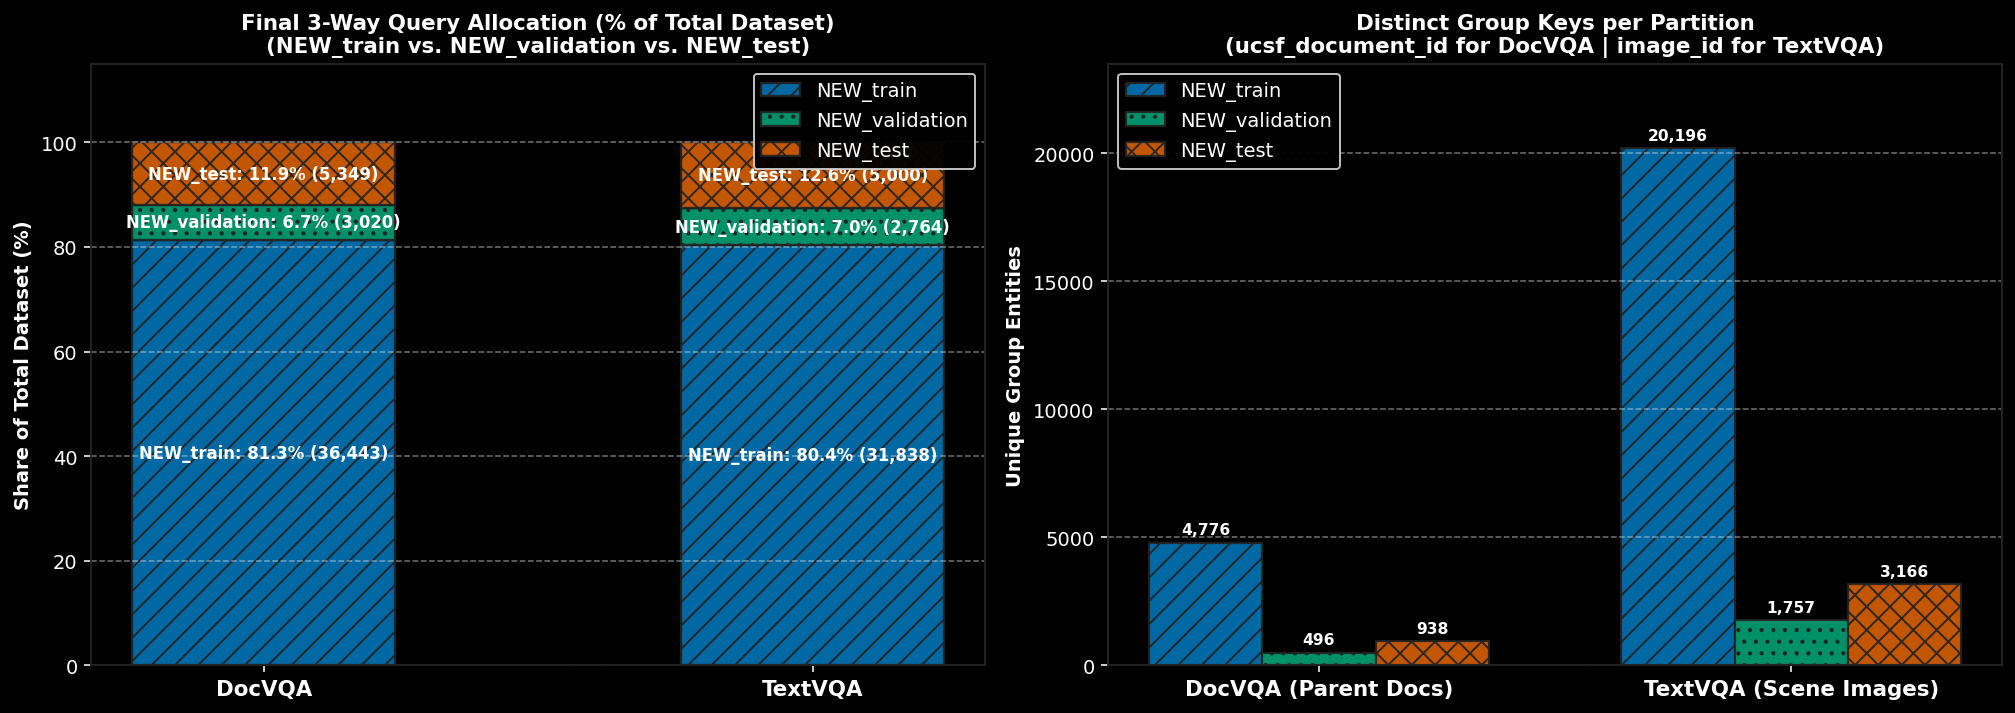

In [11]:
# ==============================================================================
# 8B. VISUALIZATION: FINAL 3-WAY PARTITION DISTRIBUTION (NEW_train / NEW_val / NEW_test)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.2), dpi=140)

splits_order = ["train", "validation", "test"]
split_labels = ["NEW_train", "NEW_validation", "NEW_test"]
split_colors = [OKABE_ITO["blue"], OKABE_ITO["green"], OKABE_ITO["vermilion"]]
split_hatches = ["//", "..", "xx"]

x_pos = np.arange(2)
bar_w = 0.48
bottoms = np.zeros(2)

for sp, s_lbl, col, ht in zip(splits_order, split_labels, split_colors, split_hatches):
    shares = np.array([
        (df_doc_split["NEW_split"] == sp).mean() * 100,
        (df_txt_split["NEW_split"] == sp).mean() * 100,
    ])
    counts = [
        int((df_doc_split["NEW_split"] == sp).sum()),
        int((df_txt_split["NEW_split"] == sp).sum()),
    ]
    bars = ax1.bar(
        x_pos, shares, width=bar_w, bottom=bottoms,
        color=col, edgecolor=OKABE_ITO["dark_slate"], linewidth=1.2, hatch=ht, alpha=0.92, label=s_lbl
    )
    for b, sh, cnt, bot in zip(bars, shares, counts, bottoms):
        ax1.annotate(
            f"{s_lbl}: {sh:.1f}% ({cnt:,})",
            xy=(b.get_x() + b.get_width() / 2, bot + sh / 2),
            ha="center", va="center", color="#FFFFFF", fontweight="bold", fontsize=8.5,
        )
    bottoms += shares

ax1.set_title("Final 3-Way Query Allocation (% of Total Dataset)\n(NEW_train vs. NEW_validation vs. NEW_test)", fontsize=11)
ax1.set_ylabel("Share of Total Dataset (%)")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(["DocVQA", "TextVQA"], fontweight="bold", fontsize=11)
ax1.set_ylim(0, 115)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color=OKABE_ITO["light_grid"])
ax1.legend(loc="upper right", framealpha=0.95)

# Panel B: Distinct Group Keys per Partition
w = 0.24
for idx_sp, (sp, s_lbl, col, ht) in enumerate(zip(splits_order, split_labels, split_colors, split_hatches)):
    grp_counts = [
        df_doc_split[df_doc_split["NEW_split"] == sp]["ucsf_document_id"].nunique(),
        df_txt_split[df_txt_split["NEW_split"] == sp]["image_id"].nunique(),
    ]
    bars_g = ax2.bar(
        x_pos + (idx_sp - 1) * w, grp_counts, width=w,
        color=col, edgecolor=OKABE_ITO["dark_slate"], linewidth=1.1, hatch=ht, alpha=0.92, label=s_lbl
    )
    for b in bars_g:
        h = int(b.get_height())
        ax2.annotate(
            f"{h:,}",
            xy=(b.get_x() + b.get_width() / 2, h),
            xytext=(0, 3), textcoords="offset points",
            ha="center", va="bottom", fontsize=8.0, fontweight="bold",
        )

ax2.set_title("Distinct Group Keys per Partition\n(ucsf_document_id for DocVQA | image_id for TextVQA)", fontsize=11)
ax2.set_ylabel("Unique Group Entities")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(["DocVQA (Parent Docs)", "TextVQA (Scene Images)"], fontweight="bold", fontsize=11)
ax2.set_ylim(0, 23500)
ax2.grid(axis="y", linestyle="--", alpha=0.5, color=OKABE_ITO["light_grid"])
ax2.legend(loc="upper left", framealpha=0.95)

plt.tight_layout()
final_fig_path = REL_FIGURES_DIR / "final_split_partition_summary.png"
plt.savefig(final_fig_path, dpi=150, bbox_inches="tight")
print(f"[Saved Figure] {final_fig_path.as_posix()}")
plt.show()


### AGGREGATE DATA (leave this section blank for now)
